In [4]:
import pandas as pd

df = pd.read_csv("/Users/user/PycharmProjects/Sms Spam Classifier/SMSSpamCollection", sep="\t", header=None, names=["label", "message"], encoding="latin-1")
print(df.shape)
print(df["label"].value_counts())
df.head()

(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
print("Missing Values:",df.isnull().sum())
print("Duplicate Values", df.duplicated().sum())


Missing Values: label      0
message    0
dtype: int64
Duplicate Values 403


In [6]:
df=df.drop_duplicates(keep="first").reset_index(drop=True)
df.shape


df['target']=df['label'].map({"ham":0,"spam":1})
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True)*100)


target
0    4516
1     653
Name: count, dtype: int64
target
0    87.366996
1    12.633004
Name: proportion, dtype: float64


In [7]:
df['length']=df['message'].apply(len)
df.head()


,label,message,target,length
0,ham,"Go until jurong point, crazy.. Available only ...",0,111
1,ham,Ok lar... Joking wif u oni...,0,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155
3,ham,U dun say so early hor... U c already then say...,0,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61


In [8]:
print(df.groupby("label")["length"].describe())
df.head

        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4516.0   70.987600  56.736845   2.0   34.0   53.0   91.0  910.0
spam    653.0  138.130168  29.937254  13.0  132.0  149.0  157.0  224.0


<bound method NDFrame.head of      label                                            message  target  length
0      ham  Go until jurong point, crazy.. Available only ...       0     111
1      ham                      Ok lar... Joking wif u oni...       0      29
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...       1     155
3      ham  U dun say so early hor... U c already then say...       0      49
4      ham  Nah I don't think he goes to usf, he lives aro...       0      61
...    ...                                                ...     ...     ...
5164  spam  This is the 2nd time we have tried 2 contact u...       1     161
5165   ham              Will Ã¼ b going to esplanade fr home?       0      37
5166   ham  Pity, * was in mood for that. So...any other s...       0      57
5167   ham  The guy did some bitching but I acted like i'd...       0     125
5168   ham                         Rofl. Its true to its name       0      26

[5169 rows x 4 columns]>

In [9]:
import nltk
import string
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

ps = PorterStemmer()
stop_words = set(stopwords.words("english"))

def transform_text(text):
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = [w for w in tokens if w.isalnum()]
    tokens = [w for w in tokens if w not in stop_words]
    tokens = [ps.stem(w) for w in tokens]
    return " ".join(tokens)

# Test on one message first
print(df["message"][10])
print(transform_text(df["message"][10]))

# Apply to all messages
df["transformed"] = df["message"].apply(transform_text)
df[["message", "transformed"]].head()

[nltk_data] Downloading package punkt to /Users/user/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /Users/user/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /Users/user/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.
gon na home soon want talk stuff anymor tonight k cri enough today


,message,transformed
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

X = df["transformed"]
y = df["target"]

# Split first, so the test set stays unseen
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2, stratify=y
)

# Fit TF-IDF on training data only
tfidf = TfidfVectorizer(max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train shape:", X_train_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)
print("Sample features:", tfidf.get_feature_names_out()[:15])

Train shape: (4135, 3000)
Test shape: (1034, 3000)
Sample features: ['0207' '02073162414' '021' '050703' '0578' '07123456789' '07xxxxxxxxx'
 '0800' '08000407165' '08000776320' '08000839402' '08000930705'
 '08000938767' '08001950382' '08002888812']


In [12]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": LinearSVC(),
}

results = []
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    # ROC-AUC needs scores, not hard predictions
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
    })

results_df = pd.DataFrame(results).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Naive Bayes,0.9778,1.0000,0.8244,0.9038,0.9855
1,Logistic Regression,0.9710,0.9903,0.7786,0.8718,0.9840
2,SVM,0.9923,1.0000,0.9389,0.9685,0.9841


In [13]:
from sklearn.metrics import confusion_matrix
import pandas as pd

rates=[]

for name,model in models.items():
  model.fit(X_train_tfidf,y_train)
  y_pred=model.predict(X_test_tfidf)
  cm=confusion_matrix(y_test,y_pred);
  tn,fp,fn,tp=cm.ravel()
  rates.append({
      "Model":name,
      "True Negative":tn,
      "False Positive":fp,
      "False Negative":fn,
      "True Positive":tp,
      "Accuracy":(tp+tn)/(tp+tn+fp+fn),
      "Misclassification Rate":(fp+fn)/(tp+tn+fp+fn),
      "Precision":tp/(tp+fp)})
pd.DataFrame(rates).round(4)

,Model,True Negative,False Positive,False Negative,True Positive,Accuracy,Misclassification Rate,Precision
0,Naive Bayes,903,0,23,108,0.9778,0.0222,1.0000
1,Logistic Regression,902,1,29,102,0.9710,0.0290,0.9903
2,SVM,903,0,8,123,0.9923,0.0077,1.0000


Matplotlib is building the font cache; this may take a moment.


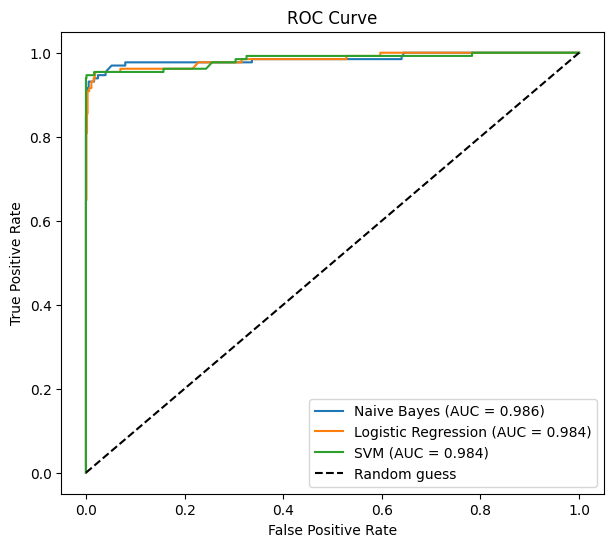

In [14]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
for name, model in models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        scores = model.decision_function(X_test_tfidf)
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [19]:
import pickle

pickle.dump(tfidf, open("vectorizer.pkl", "wb"))
pickle.dump(models["SVM"], open("model.pkl", "wb"))
print("Saved")

Saved
